# Stage 2 verification — human agreement

The rule-based cause classifier is compared against manual annotation. For 50 test clips, the author recorded the visible markers and a cause label in a separate annotation sheet. The notebook reports percentage agreement and Cohen’s κ between the human labels and the rule outputs.

**Clips.** Following the proposal's contingency plan, the clips originate from DiASEE itself. **Features for the rules:** the unscaled merged windows (script-02 output).

The rule labels are recorded in `stage2_annotation.csv`

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import cohen_kappa_score, confusion_matrix

from attention_lapse_detection.detection.classify_cause import (
    BLINK_RATE_MAX,
    FATIGUE,
    MIND_WANDERING,
    PERCLOS_MAX,
    PROLONGED_CLOSURE_S,
    UNKNOWN,
    YAWN_MIN_S,
    cause_evidence,
    classify_cause,
)
from attention_lapse_detection.training.metrics import participant_ids
from attention_lapse_detection.training.selection import select
from attention_lapse_detection.utils.constants import FEATURE_COLUMNS, SEED
from attention_lapse_detection.utils.data_paths import labels_csv, merged_npz
from attention_lapse_detection.utils.paths import PATHS

CAUSE_LABELS = [FATIGUE, MIND_WANDERING, UNKNOWN]
MARKERS = ["eyes_closed_often", "prolonged_eye_closure", "yawning", "elevated_blinking"]
ANNOTATION = MARKERS + ["human_label"]
SAMPLE_SIZE = 50

annotation_path = PATHS.experiments / "results/stage2_annotation.csv"
blind_path = PATHS.experiments / "results/stage2_annotation_blind.csv"

In [34]:
all_runs = pd.read_csv(PATHS.experiments / "results/thesis_runs.csv")

MODEL, FPS, WINDOW = select(all_runs)

print(f"Stage 2 ({MODEL}) {FPS}fps/{WINDOW}s")

Stage 2 (gru_uni_attention) 10fps/10s


### Sample

The sampling frame consists of all test clips that DAiSEE labels as disengaged and that are long enough for the build. From the sorted IDs, 50 clips were taken by simple random sampling without replacement using seed 42, so every run draws the same clips.

In [35]:
with np.load(merged_npz(FPS, "Test", WINDOW), allow_pickle=True) as merged_chunks:
    frames_by_clip = dict(zip(merged_chunks["video_id"], merged_chunks["X"]))

engagement = pd.read_csv(labels_csv("Test")).set_index("ClipID").Engagement
disengaged = engagement.index[engagement.eq(0)]

pool = [clip_id for clip_id in disengaged if clip_id in frames_by_clip]


def clip_rows(clip_id: str) -> list[dict]:
    return [dict(zip(FEATURE_COLUMNS, frame)) for frame in frames_by_clip[clip_id]]


annotations_sheet = pd.read_csv(annotation_path)
marks = annotations_sheet[MARKERS].astype(int)
human_labels = annotations_sheet.human_label

assert set(human_labels) <= set(CAUSE_LABELS), "false labels present"

assert annotations_sheet.rule_label.tolist() == [
    classify_cause(clip_rows(clip_id), fps=FPS)
    for clip_id in annotations_sheet.video_id
], "the rules no longer reproduce the stored rule labels"


print(
    f"{len(annotations_sheet)} annotated clips ({len(set(participant_ids(annotations_sheet.video_id)))} participants) "
    f"from {len(pool)} of {len(disengaged)} disengaged test clips in the build"
)

50 annotated clips (13 participants) from 84 of 88 disengaged test clips in the build


### Agreement

In [36]:
rule_labels = annotations_sheet.rule_label
matches = rule_labels == human_labels

agreement = matches.mean()

kappa = cohen_kappa_score(human_labels, rule_labels, labels=CAUSE_LABELS)

counts_human = human_labels.value_counts().reindex(CAUSE_LABELS, fill_value=0)
counts_rule = rule_labels.value_counts().reindex(CAUSE_LABELS, fill_value=0)

expected = float(np.dot(counts_human, counts_rule)) / len(annotations_sheet) ** 2

participants = participant_ids(annotations_sheet.video_id.to_numpy())
groups = [np.flatnonzero(participants == pid) for pid in np.unique(participants)]

rng = np.random.default_rng(0)
boot = []

for _ in range(2000):
    picked_rows = np.concatenate([groups[k] for k in rng.integers(0, len(groups), len(groups))])

    boot_kappa = cohen_kappa_score(
        human_labels.iloc[picked_rows], rule_labels.iloc[picked_rows], labels=CAUSE_LABELS
    )

    boot.append(boot_kappa)

kappa_ci = np.nanpercentile(boot, [2.5, 97.5])

print(f"Agreement: {agreement:.1%} ({matches.sum()}/{len(annotations_sheet)}), expected by chance {expected:.1%}")
print(f"Cohe's kappa: {kappa:.3f}, 95% CI [{kappa_ci[0]:.3f}, {kappa_ci[1]:.3f}]")
print(f"CI from resampling {len(groups)} participants")

confusion = pd.DataFrame(
    confusion_matrix(human_labels, rule_labels, labels=CAUSE_LABELS),
    index=CAUSE_LABELS,
    columns=CAUSE_LABELS,
)

print("Confusion matrix (rows: human label, columns: rule label)")
confusion

Agreement: 74.0% (37/50), expected by chance 39.5%
Cohe's kappa: 0.570, 95% CI [0.269, 0.776]
CI from resampling 13 participants
Confusion matrix (rows: human label, columns: rule label)


,likely fatigue,likely mind wandering,unknown
likely fatigue,8,2,3
likely mind wandering,1,7,1
unknown,2,4,22


In [37]:
evidence = pd.DataFrame([cause_evidence(clip_rows(clip_id), fps=FPS) for clip_id in annotations_sheet.video_id])

traced = annotations_sheet[["video_id", "rule_label", "human_label"]].join(evidence)
disagreements = traced[traced.rule_label != traced.human_label]

print(f"{len(disagreements)} disagreements:")
disagreements.round(2)

13 disagreements:


,video_id,rule_label,human_label,face_valid_ratio,perclos,longest_closure_s,longest_yawn_s,blink_rate
3,5000671041.avi,likely mind wandering,unknown,1.00,0.11,0.4,0.0,30.00
6,8264120243.avi,likely fatigue,unknown,0.95,0.06,0.2,0.6,25.26
13,5000671048.avi,likely mind wandering,unknown,1.00,0.10,0.2,0.0,30.00
18,5000671061.avi,unknown,likely fatigue,1.00,0.16,1.0,0.0,24.00
22,5000951023.avi,unknown,likely fatigue,1.00,0.15,0.8,0.0,24.00
25,9877360120.avi,likely mind wandering,unknown,1.00,0.22,1.1,0.3,42.00
27,8264120265.avi,likely fatigue,likely mind wandering,1.00,0.15,0.3,0.7,48.00
30,907001480.mp4,likely mind wandering,unknown,1.00,0.10,0.3,0.0,36.00
31,5100342028.avi,unknown,likely fatigue,1.00,0.03,0.1,0.0,12.00
37,5100401034.avi,likely fatigue,unknown,1.00,0.34,1.0,0.0,30.00


For each human rule label pair, the number of clips meeting each threshold was counted. Where both categories applied, fatigue took precedence over elevated blinking.

In [38]:
measured = pd.DataFrame(
    {
        "eyes_closed_often": traced.perclos > PERCLOS_MAX,
        "prolonged_eye_closure": traced.longest_closure_s > PROLONGED_CLOSURE_S,
        "yawning": traced.longest_yawn_s >= YAWN_MIN_S,
        "elevated_blinking": traced.blink_rate > BLINK_RATE_MAX,
    }
).astype(int)

pairs = [traced.human_label, traced.rule_label]

summary = measured.groupby(pairs).sum()
summary.insert(0, "clips", measured.groupby(pairs).size())

summary

clips  eyes_closed_often  \
human_label           rule_label                                        
likely fatigue        likely fatigue             8                  4   
                      likely mind wandering      2                  0   
                      unknown                    3                  0   
likely mind wandering likely fatigue             1                  0   
                      likely mind wandering      7                  0   
                      unknown                    1                  0   
unknown               likely fatigue             2                  1   
                      likely mind wandering      4                  0   
                      unknown                   22                  0   

                                             prolonged_eye_closure  yawning  \
human_label           rule_label                                              
likely fatigue        likely fatigue                             1        5   
                      likely mind wandering                      0        0   
                      unknown                                    0        0   
likely mind wandering likely fatigue                             0        1   
                      likely mind wandering                      0        0   
                      unknown                                    0        0   
unknown               likely fatigue                             0        1   
                      likely mind wandering                      0        0   
                      unknown                                    0        0   

                                             elevated_blinking  
human_label           rule_label                                
likely fatigue        likely fatigue                         6  
                      likely mind wandering                  2  
                      unknown                                0  
likely mind wandering likely fatigue                         1  
                      likely mind wandering                  7  
                      unknown                                0  
unknown               likely fatigue                         2  
                      likely mind wandering                  4  
                      unknown                                0

### Visible marker annotation


`eyes_closed_often`: PERCLOS > 0.24 
`prolonged_eye_closure`: continuous closure > 5s
`yawning`: MAR > 0.60 continuously for >= 0.50 s
`elevated_blinking`: blink rate > 25/min 


In [39]:
by_human = marks.groupby(human_labels).sum()
by_human.insert(0, "clips", marks.groupby(human_labels).size())

by_human

,clips,eyes_closed_often,prolonged_eye_closure,yawning,elevated_blinking
human_label,,,,,
likely fatigue,13,9,9,4,2
likely mind wandering,9,1,0,0,9
unknown,28,0,0,0,0


In [40]:

by_pair = marks.groupby(pairs).sum()
by_pair.insert(0, "clips", marks.groupby(pairs).size())
by_pair

clips  eyes_closed_often  \
human_label           rule_label                                        
likely fatigue        likely fatigue             8                  4   
                      likely mind wandering      2                  2   
                      unknown                    3                  3   
likely mind wandering likely fatigue             1                  0   
                      likely mind wandering      7                  1   
                      unknown                    1                  0   
unknown               likely fatigue             2                  0   
                      likely mind wandering      4                  0   
                      unknown                   22                  0   

                                             prolonged_eye_closure  yawning  \
human_label           rule_label                                              
likely fatigue        likely fatigue                             4        4   
                      likely mind wandering                      2        0   
                      unknown                                    3        0   
likely mind wandering likely fatigue                             0        0   
                      likely mind wandering                      0        0   
                      unknown                                    0        0   
unknown               likely fatigue                             0        0   
                      likely mind wandering                      0        0   
                      unknown                                    0        0   

                                             elevated_blinking  
human_label           rule_label                                
likely fatigue        likely fatigue                         2  
                      likely mind wandering                  0  
                      unknown                                0  
likely mind wandering likely fatigue                         1  
                      likely mind wandering                  7  
                      unknown                                1  
unknown               likely fatigue                         0  
                      likely mind wandering                  0  
                      unknown                                0

In [41]:
marker_kappa = [
    cohen_kappa_score(marks[m], measured[m], labels=[0, 1]) for m in MARKERS
]

marker_vs_rule = pd.DataFrame(
    {
        "seen": marks.sum(),
        "measured": measured.sum(),
        "seen_only": ((marks == 1) & (measured == 0)).sum(),
        "measured_only": ((marks == 0) & (measured == 1)).sum(),
        "both": ((marks == 1) & (measured == 1)).sum(),
        "neither": ((marks == 0) & (measured == 0)).sum(),
    }
)

marker_vs_rule["agreement"] = (marker_vs_rule.both + marker_vs_rule.neither) / len(
    marks
)

marker_vs_rule["kappa"] = marker_kappa
marker_vs_rule.round(3)

,seen,measured,seen_only,measured_only,both,neither,agreement,kappa
eyes_closed_often,10,5,6,1,4,39,0.86,0.462
prolonged_eye_closure,9,1,8,0,1,41,0.84,0.170
yawning,4,7,0,3,4,43,0.94,0.696
elevated_blinking,11,22,1,12,10,27,0.74,0.443


### Figure 7.3 Marker confusion matrices


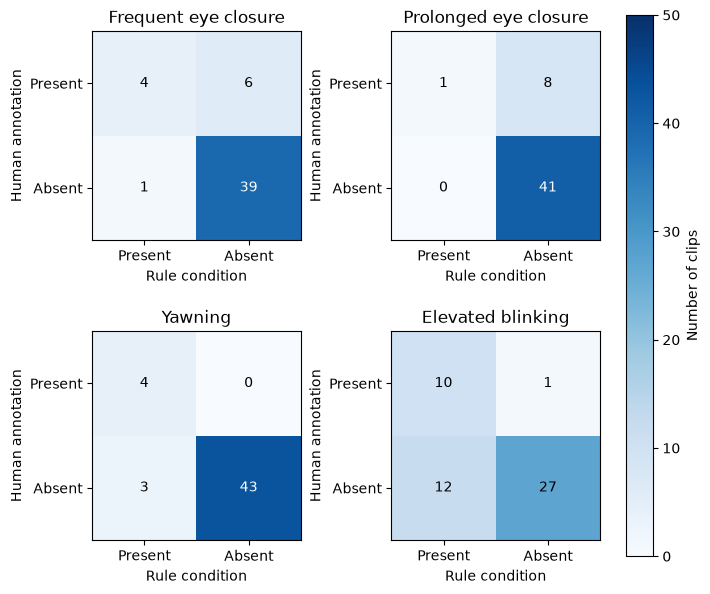

In [42]:
marker_titles = [
    "Frequent eye closure",
    "Prolonged eye closure",
    "Yawning",
    "Elevated blinking",
]

marker_matrices = [
    np.array([[row.both, row.seen_only], [row.measured_only, row.neither]])
    for row in marker_vs_rule.loc[MARKERS].itertuples()
]

matrix_fig, matrix_axes = plt.subplots(2, 2, figsize=(7, 6), layout="constrained")

for ax, matrix, title in zip(matrix_axes.flat, marker_matrices, marker_titles):

    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=len(marks))

    ax.set_xticks([0, 1], ["Present", "Absent"])
    ax.set_yticks([0, 1], ["Present", "Absent"])

    ax.set_xlabel("Rule condition")
    ax.set_ylabel("Human annotation")

    ax.set_title(title)
    
    for (row, column), count in np.ndenumerate(matrix):

        if count >= 30:
            text_color = "white"
        else:
            text_color = "black"
        
        ax.text(
            column,
            row,
            str(count),
            ha="center",
            va="center",
            color=text_color,
        )

matrix_fig.colorbar(
    matrix_axes[0, 0].images[0], ax=matrix_axes, label="Number of clips"
)

plt.show()

## Figure 7.2 Confusion matrix

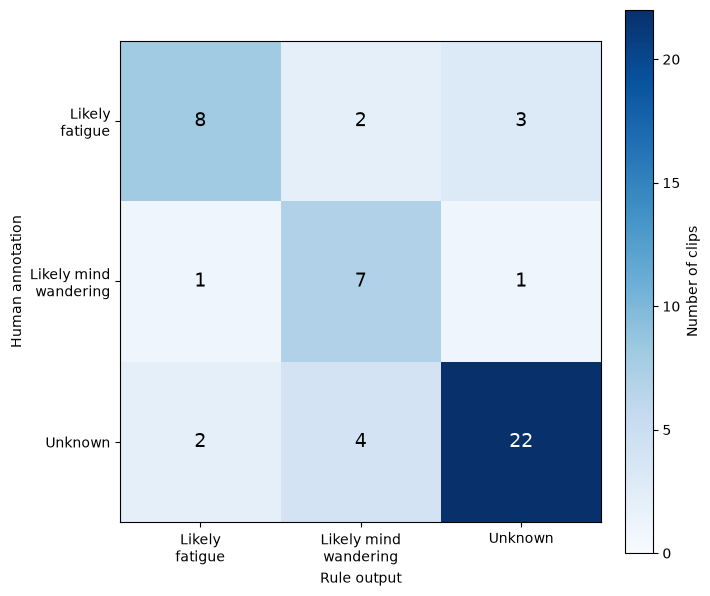

In [43]:
cause_counts = confusion.to_numpy()

cause_ticks = ["Likely\nfatigue", "Likely mind\nwandering", "Unknown"]

cause_fig, cause_ax = plt.subplots(figsize=(7, 6), layout="constrained")

heatmap = cause_ax.imshow(cause_counts, cmap="Blues", vmin=0)

cause_ax.set_xticks([0, 1, 2], cause_ticks)
cause_ax.set_yticks([0, 1, 2], cause_ticks)

cause_ax.set_xlabel("Rule output")
cause_ax.set_ylabel("Human annotation")

for (row, column), count in np.ndenumerate(cause_counts):
    if count > cause_counts.max() / 2:
        text_color = "white"
    else:
        text_color = "black"
    cause_ax.text(column, row, count, ha="center", va="center", fontsize=14, color=text_color)

cause_fig.colorbar(
    heatmap,
    ax=cause_ax,
    label="Number of clips",
    ticks=range(0, cause_counts.max() + 1, 5),
)

plt.show()